In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/home/ammar/AI Track/ai-foundation-portfolio/Machine-Learning/Linear Regression/Datasets/placement.csv")

In [3]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [4]:
from sklearn.model_selection import train_test_split


In [5]:
X_train, X_test, y_train, y_test = train_test_split(df['cgpa'].values,df['package'].values,test_size=0.3,random_state=42)

In [6]:
X_train.shape, X_test.shape

((140,), (60,))

In [35]:
class MyLinearRegression:
    def __init__(self):
        self.m = None
        self.b = None

    def fit(self,X_train,y_train):
        numerator = 0
        denominator = 0

        X_train_mean = np.mean(X_train)
        y_train_mean = np.mean(y_train)

        for i in range(X_train.shape[0]): # shape[0] --> extracts the number of rows
            
            
            numerator = numerator + (X_train[i] - X_train_mean)* (y_train[i] - y_train_mean) # finding the covariance
            denominator = denominator + (X_train[i] - X_train_mean)*(X_train[i] - X_train_mean) # finding the variance 
        # m = ∑(xi−x̄)(yi−ȳ)/∑(xi−x̄)^2 = Cov(x,y)/Var(x)
        
        self.m = numerator/denominator
        self.b = y_train.mean() - (self.m*X_train.mean())

    def predict(self,X_test):
        return self.m*X_test + self.b
            
        

In [36]:
lr = MyLinearRegression()

In [37]:
lr.fit(X_train,y_train)

In [57]:
lr.predict(6.89)

np.float64(2.94766290555182)

## Scikit Learn's Linear Regression

In [39]:
from sklearn.linear_model import LinearRegression
#this class implements linear regression using OLS (Ordinary Least Squares)

In [40]:
lr_2 = LinearRegression()

In [44]:
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(df['cgpa'], df['package'], test_size=0.3,random_state=42)

In [46]:
lr_2.fit(pd.DataFrame(X_train_2), y_train_2)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.57]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['cgpa']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.9809
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


### The output is exactly the same

In [47]:
lr.predict(6.89)

np.float64(2.94766290555182)

<Axes: xlabel='cgpa', ylabel='package'>

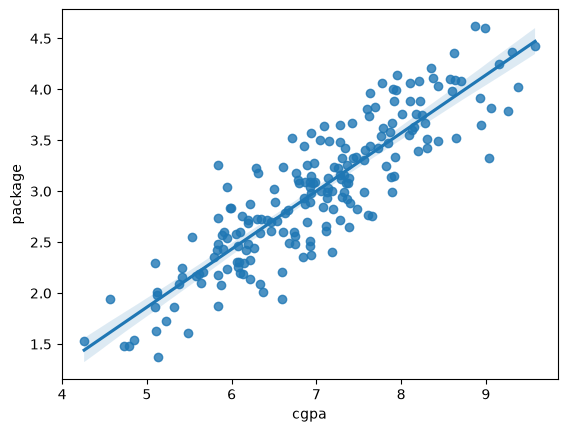

In [55]:
sns.regplot(data=df, x=df['cgpa'], y=df['package'])